# Huấn luyện và đánh giá mô hình nguy cơ tiểu đường

Notebook này **không huấn luyện lại** từ đầu (quy trình đầy đủ gồm CV, tuning, hiệu chuẩn nằm ở
`models/training_pipeline.py` và `scripts/train_diabetes_model.py`). Notebook tải lại dữ liệu BRFSS 2015, tái tạo
đúng cách chia 60/20/20 (`random_state=42`, phân tầng) rồi đánh giá artifact đã huấn luyện
`artifacts/risk_model.joblib`. Mỗi hình nằm ngay sau cell sinh ra nó và được lưu vào `report/images/`;
mỗi bảng được ghi ra `report/tables/*.tex` để báo cáo LaTeX `\input` trực tiếp.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "models").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUT = ROOT / "report" / "images"
TAB = ROOT / "report" / "tables"
OUT.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
metrics = json.loads((ROOT / "artifacts" / "metrics.json").read_text(encoding="utf-8"))
vn = lambda x, d=4: f"{x:.{d}f}".replace(".", ",")      # số thập phân kiểu Việt Nam
print(metrics["model_version"], metrics["rows_total"], metrics["selected_threshold"])

mlp-20261101145441 253680 0.23906


## 1. Dữ liệu và cách chia tập

152208 50736 50736 | positive rate: 0.1393


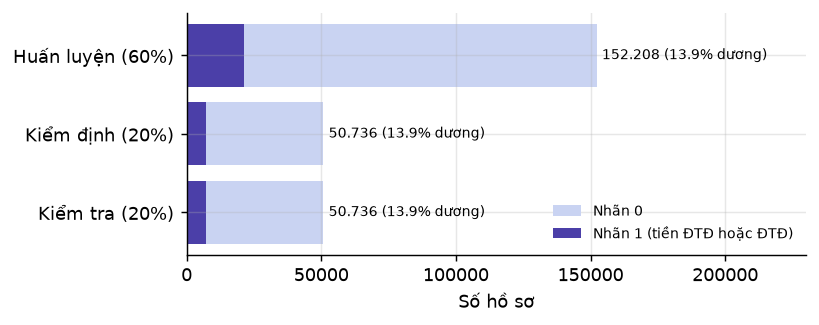

In [2]:
from sklearn.model_selection import train_test_split
from models.training_pipeline import FEATURE_NAMES, TARGET_COLUMN, RANDOM_STATE, TEST_SIZE, VALIDATION_SIZE

df = pd.read_csv(ROOT / "data" / "training" / "diabetes_binary_health_indicators_BRFSS2015.csv")
X, y = df[FEATURE_NAMES], df[TARGET_COLUMN].astype(int)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=VALIDATION_SIZE, random_state=RANDOM_STATE, stratify=y_dev)
print(len(X_train), len(X_val), len(X_test), "| positive rate:", round(y.mean(), 4))
assert (len(X_train), len(X_val), len(X_test)) == (metrics["rows_train"], metrics["rows_validation"], metrics["rows_test"])

fig, ax = plt.subplots(figsize=(6.4, 2.6))
sizes = [len(X_train), len(X_val), len(X_test)]
pos = [y_train.sum(), y_val.sum(), y_test.sum()]
names = ["Huấn luyện (60%)", "Kiểm định (20%)", "Kiểm tra (20%)"]
ax.barh(names[::-1], sizes[::-1], color="#c9d3f2", label="Nhãn 0")
ax.barh(names[::-1], pos[::-1], color="#4b3fa8", label="Nhãn 1 (tiền ĐTĐ hoặc ĐTĐ)")
for i, (s, p) in enumerate(zip(sizes[::-1], pos[::-1])):
    ax.text(s + 2000, i, f"{s:,} ({p/s:.1%} dương)".replace(",", "."), va="center", fontsize=8)
ax.set_xlim(0, 230000); ax.set_xlabel("Số hồ sơ"); ax.legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig_split.png"); plt.show()

## 2. So sánh các mô hình ứng viên (từ `metrics.json`)

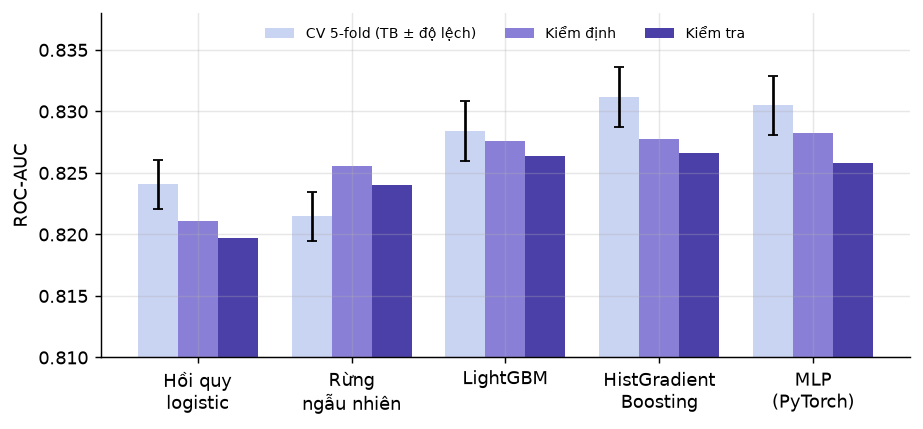

                             cv      val     test
logistic_regression     0.82406  0.82112  0.81971
random_forest           0.82146  0.82559  0.82398
lightgbm                0.82839  0.82762  0.82641
hist_gradient_boosting  0.83116  0.82779  0.82658
mlp                     0.83049  0.82828  0.82581


In [3]:
order = ["logistic_regression", "random_forest", "lightgbm", "hist_gradient_boosting", "mlp"]
labels = {"logistic_regression": "Hồi quy\nlogistic", "random_forest": "Rừng\nngẫu nhiên", "lightgbm": "LightGBM",
          "hist_gradient_boosting": "HistGradient\nBoosting", "mlp": "MLP\n(PyTorch)"}
M = metrics["metrics"]
cv = [M[m]["cv"]["roc_auc_mean"] for m in order]
cv_sd = [M[m]["cv"]["roc_auc_std"] for m in order]
va = [M[m]["validation"]["roc_auc"] for m in order]
te = [M[m]["test"]["roc_auc"] for m in order]
x = np.arange(len(order)); w = .26
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.bar(x - w, cv, w, yerr=cv_sd, capsize=3, label="CV 5-fold (TB ± độ lệch)", color="#c9d3f2")
ax.bar(x, va, w, label="Kiểm định", color="#8a7fd6")
ax.bar(x + w, te, w, label="Kiểm tra", color="#4b3fa8")
ax.set_ylim(.81, .838); ax.set_xticks(x, [labels[m] for m in order]); ax.set_ylabel("ROC-AUC")
ax.legend(fontsize=8, frameon=False, ncol=3, loc="upper center")
fig.tight_layout(); fig.savefig(OUT / "fig_model_compare.png"); plt.show()

# Bảng LaTeX cho báo cáo (Bảng kết quả năm mô hình)
names_vi = {"logistic_regression": "Hồi quy logistic", "random_forest": "Rừng ngẫu nhiên", "lightgbm": "LightGBM",
            "hist_gradient_boosting": "HistGradientBoosting", "mlp": r"\textbf{MLP (được chọn)}"}
rows = []
for m in order:
    t = M[m]["test"]
    rows.append(f"{names_vi[m]} & ${vn(M[m]['cv']['roc_auc_mean'])}\\pm{vn(M[m]['cv']['roc_auc_std'])}$ & "
                f"{vn(M[m]['validation']['roc_auc'])} & {vn(t['roc_auc'])} & {vn(t['average_precision'], 3)} & {vn(t['brier_score'])} \\\\")
tex = ("\\begin{tabular}{@{}lccccc@{}}\n\\toprule\n"
       "\\textbf{Mô hình} & \\textbf{CV AUC} & \\textbf{Kiểm định} & \\textbf{Kiểm tra} & \\textbf{AP (kiểm tra)} & \\textbf{Brier}\\\\\n\\midrule\n"
       + "\n".join(rows) + "\n\\bottomrule\n\\end{tabular}\n")
(TAB / "tab_models.tex").write_text(tex, encoding="utf-8")
print(pd.DataFrame({"cv": cv, "val": va, "test": te}, index=order).round(5))

## 3. Đường ROC và Precision–Recall của mô hình được chọn (tập kiểm tra)

ROC-AUC 0.82581 AP 0.41441


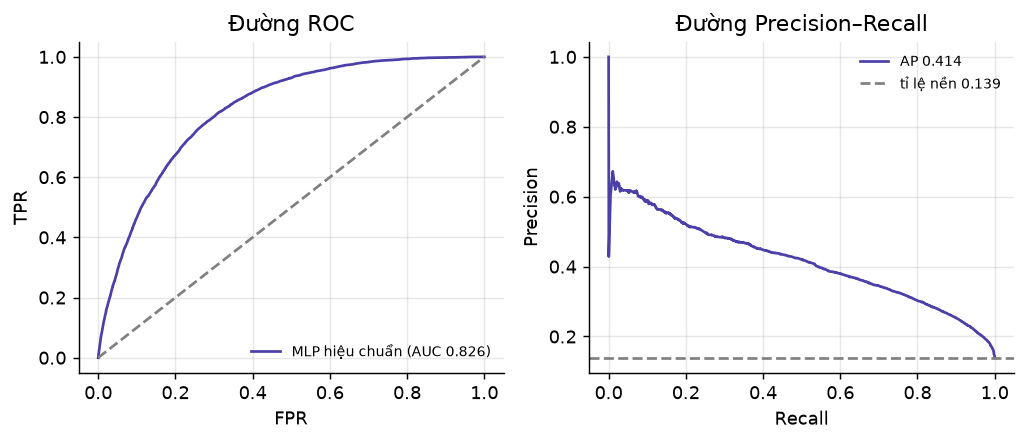

In [4]:
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
artifact = joblib.load(ROOT / "artifacts" / "risk_model.joblib")
model = artifact["model"]
p_test = model.predict_proba(X_test[artifact["feature_names"]])[:, 1]
print("ROC-AUC", round(roc_auc_score(y_test, p_test), 5), "AP", round(average_precision_score(y_test, p_test), 5))

fpr, tpr, _ = roc_curve(y_test, p_test)
prec, rec, _ = precision_recall_curve(y_test, p_test)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].plot(fpr, tpr, color="#4b3fa8", label=f"MLP hiệu chuẩn (AUC {roc_auc_score(y_test, p_test):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[0].set_title("Đường ROC"); axes[0].legend(fontsize=8, frameon=False, loc="lower right")
axes[1].plot(rec, prec, color="#4b3fa8", label=f"AP {average_precision_score(y_test, p_test):.3f}")
axes[1].axhline(y_test.mean(), ls="--", color="gray", label=f"tỉ lệ nền {y_test.mean():.3f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Đường Precision–Recall")
axes[1].legend(fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig_roc_pr.png"); plt.show()

## 4. Hiệu chuẩn xác suất (isotonic, `cv=3`)

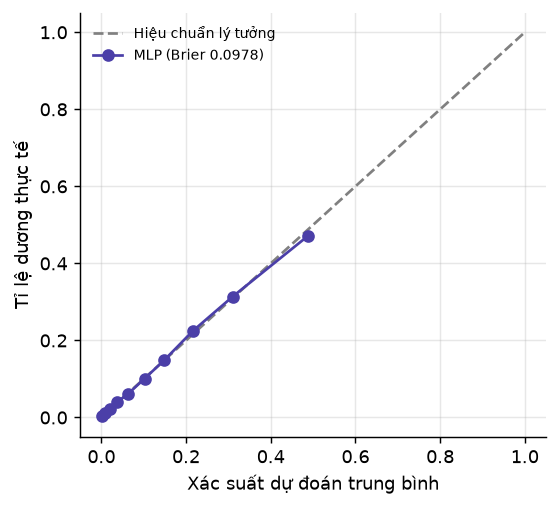

In [5]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
frac, mean_p = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.4, 4))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Hiệu chuẩn lý tưởng")
ax.plot(mean_p, frac, "o-", color="#4b3fa8", label=f"MLP (Brier {brier_score_loss(y_test, p_test):.4f})")
ax.set_xlabel("Xác suất dự đoán trung bình"); ax.set_ylabel("Tỉ lệ dương thực tế"); ax.legend(fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig_calibration.png"); plt.show()

## 5. Ngưỡng nhị phân và các mức Thấp / Trung bình / Cao

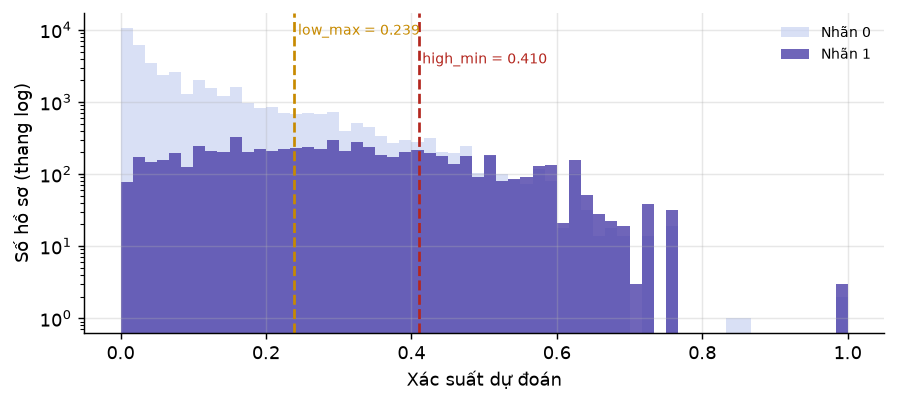

Low       39495
Medium     7371
High       3870
Name: count, dtype: int64


In [6]:
bands = metrics["risk_bands"]; thr = metrics["selected_threshold"]
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0, 1, 61)
ax.hist(p_test[y_test == 0], bins=bins, alpha=.7, color="#c9d3f2", label="Nhãn 0")
ax.hist(p_test[y_test == 1], bins=bins, alpha=.8, color="#4b3fa8", label="Nhãn 1")
ax.set_yscale("log")
ax.axvline(bands["low_max"], color="#c78a00", ls="--"); ax.axvline(bands["high_min"], color="#b3261e", ls="--")
ymax = ax.get_ylim()[1]
ax.text(bands["low_max"] + .005, ymax * .5, f"low_max = {bands['low_max']:.3f}", color="#c78a00", fontsize=8)
ax.text(bands["high_min"] + .005, ymax * .2, f"high_min = {bands['high_min']:.3f}", color="#b3261e", fontsize=8)
ax.set_xlabel("Xác suất dự đoán"); ax.set_ylabel("Số hồ sơ (thang log)"); ax.legend(fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig_bands.png"); plt.show()

from tools.risk_classifier import classify_risk
level = pd.Series([classify_risk(p, bands) for p in p_test])
rows = []
for lv, name in [("Low", "Thấp"), ("Medium", "Trung bình"), ("High", "Cao")]:
    mask = (level == lv).values
    n, k = int(mask.sum()), int(y_test.values[mask].sum())
    dot = lambda v: f"{v:,}".replace(",", ".")          # dấu chấm ngăn cách hàng nghìn
    rows.append(f"{name} & {dot(n)} & {dot(k)} & {vn(100 * k / n, 1)}\\% \\\\")
tex = ("\\begin{tabular}{@{}lccc@{}}\n\\toprule\n\\textbf{Mức} & \\textbf{Số ca} & \\textbf{Nhãn 1} & \\textbf{Tỉ lệ nhãn 1}\\\\\n\\midrule\n"
       + "\n".join(rows) + "\n\\bottomrule\n\\end{tabular}\n")
(TAB / "tab_bands.tex").write_text(tex, encoding="utf-8")
print(level.value_counts())

{'tn': np.int64(36687), 'fp': np.int64(6980), 'fn': np.int64(2808), 'tp': np.int64(4261)} precision 0.3791 recall 0.6028


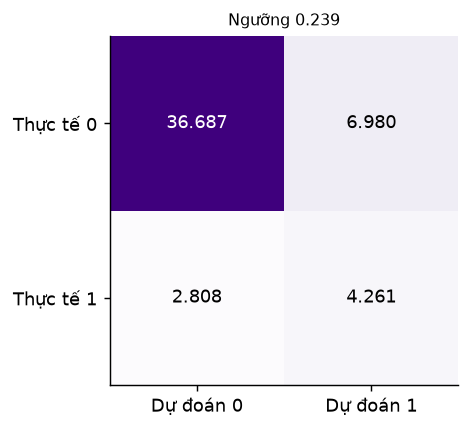

In [7]:
from sklearn.metrics import confusion_matrix
pred = (p_test >= thr).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(dict(tn=tn, fp=fp, fn=fn, tp=tp), "precision", round(tp/(tp+fp), 4), "recall", round(tp/(tp+fn), 4))
assert (tn, fp, fn, tp) == tuple(metrics["metrics"]["mlp"]["test"]["confusion_matrix"].values())

fig, ax = plt.subplots(figsize=(3.8, 3.4))
cm = np.array([[tn, fp], [fn, tp]])
ax.imshow(cm, cmap="Purples"); ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center", color="white" if cm[i, j] > 20000 else "black")
ax.set_xticks([0, 1], ["Dự đoán 0", "Dự đoán 1"]); ax.set_yticks([0, 1], ["Thực tế 0", "Thực tế 1"])
ax.set_title(f"Ngưỡng {thr:.3f}", fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "fig_confusion.png"); plt.show()

## 6. Đồ thị tri thức (bản chụp ngoại tuyến `tests/fixtures/diabetes_kb.json`)

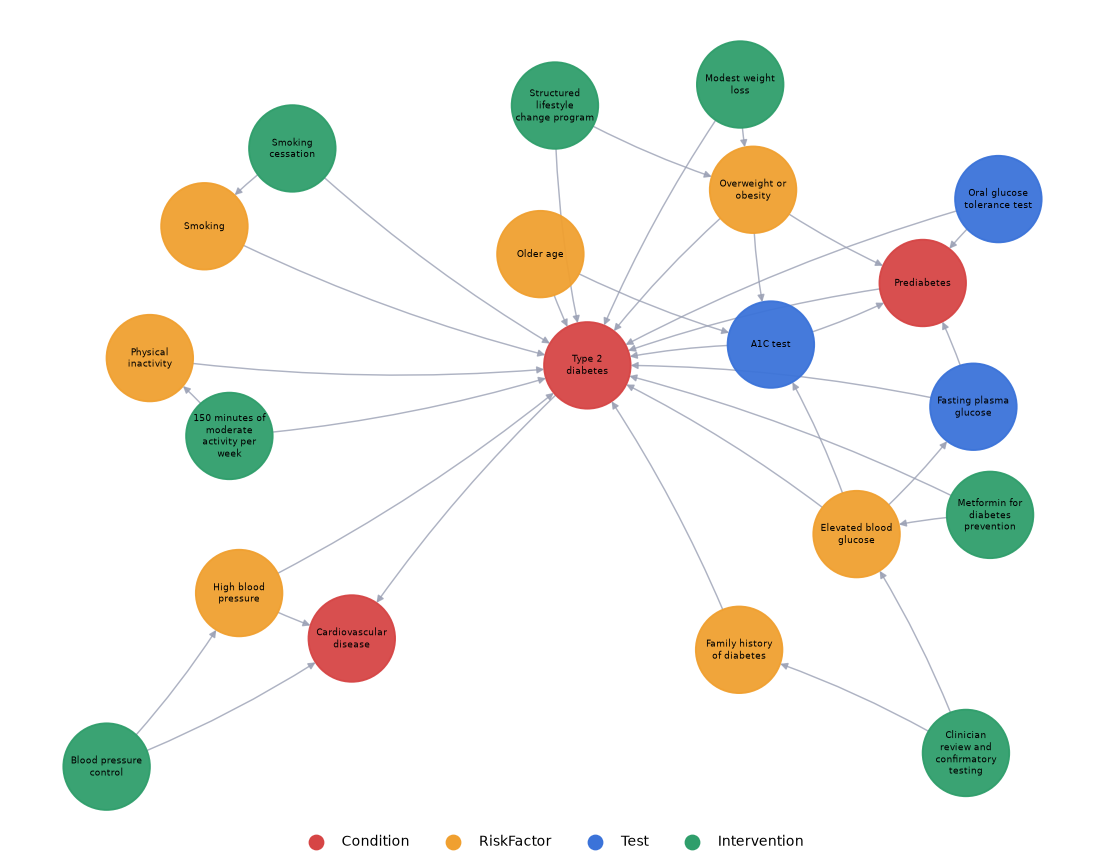

20 thực thể, 35 quan hệ, 21 bằng chứng, 5 nguồn


In [8]:
import networkx as nx
from collections import Counter
kb = json.loads((ROOT / "tests" / "fixtures" / "diabetes_kb.json").read_text(encoding="utf-8-sig"))
G = nx.DiGraph()
for e in kb["entities"]:
    G.add_node(e["id"], name=e["name"], label=e["label"])
for r in kb["relations"]:
    G.add_edge(r["from"], r["to"], type=r["type"])
colors = {"Condition": "#d64545", "RiskFactor": "#f0a030", "Test": "#3b73d9", "Intervention": "#2f9e6b"}
pos = nx.spring_layout(G.to_undirected(), seed=7, k=1.6, iterations=400)
import textwrap
fig, ax = plt.subplots(figsize=(8.6, 6.8)); ax.axis("off")
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#9aa0b4", arrows=True, arrowsize=8, width=.8, alpha=.8,
                       connectionstyle="arc3,rad=0.06", node_size=2300)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=2300, node_color=[colors[G.nodes[n]["label"]] for n in G], alpha=.95)
nx.draw_networkx_labels(G, pos, labels={n: textwrap.fill(G.nodes[n]["name"], 14) for n in G},
                        font_size=5.2, ax=ax)
for lab, c in colors.items():
    ax.scatter([], [], c=c, label=lab, s=60)
ax.legend(loc="upper center", bbox_to_anchor=(.5, 0.02), ncol=4, fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig_kg.png", dpi=170); plt.show()

# Bảng thống kê KB cho báo cáo
ent = Counter(e["label"] for e in kb["entities"]); rel = Counter(r["type"] for r in kb["relations"])
left = [f"{k} & {v}" for k, v in sorted(ent.items())] + ["Đoạn bằng chứng & " + str(len(kb["evidence"])), "Nguồn & " + str(len(kb["sources"]))]
right = [f"{k.replace('_', chr(92) + '_')} & {v}" for k, v in sorted(rel.items())]
n = max(len(left), len(right)); left += ["&"] * (n - len(left)); right += ["&"] * (n - len(right))
body = "\n".join(f"{a} & {b} \\\\" for a, b in zip(left, right))
tex = ("\\begin{tabular}{@{}lr@{\\hspace{2em}}lr@{}}\n\\toprule\n\\textbf{Nút / dữ liệu} & \\textbf{SL} & \\textbf{Loại quan hệ} & \\textbf{SL}\\\\\n\\midrule\n"
       + body + "\n\\bottomrule\n\\end{tabular}\n")
(TAB / "tab_kb.tex").write_text(tex, encoding="utf-8")
print(len(kb["entities"]), "thực thể,", len(kb["relations"]), "quan hệ,", len(kb["evidence"]), "bằng chứng,", len(kb["sources"]), "nguồn")

## 7. Policy học tăng cường (Q-learning trên môi trường mô phỏng)

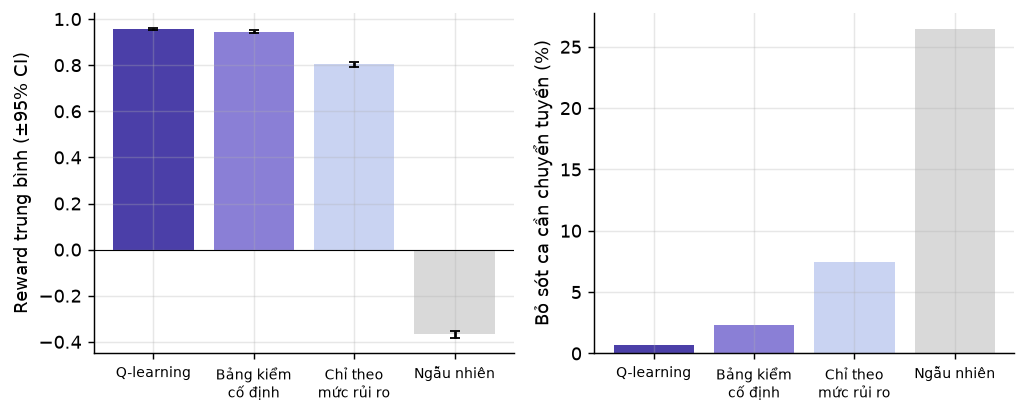

{'episodes': 20000, 'mean_reward': 0.9559, 'ci95': 0.0053, 'mean_steps': 1.778, 'under_triage_rate': 0.0065, 'over_escalation_rate': 0.0355}


In [9]:
comp = json.loads((ROOT / "artifacts" / "policy_comparison.json").read_text(encoding="utf-8"))
keys = ["q_learning", "fixed_full_checklist", "fixed_risk_only", "random"]
names = ["Q-learning", "Bảng kiểm\ncố định", "Chỉ theo\nmức rủi ro", "Ngẫu nhiên"]
rew = [comp[k]["mean_reward"] for k in keys]; ci = [comp[k]["ci95"] for k in keys]
under = [comp[k]["under_triage_rate"] * 100 for k in keys]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3))
axes[0].bar(names, rew, yerr=ci, capsize=3, color=["#4b3fa8", "#8a7fd6", "#c9d3f2", "#d9d9d9"])
axes[0].set_ylabel("Reward trung bình (±95% CI)"); axes[0].axhline(0, color="black", lw=.6)
axes[1].bar(names, under, color=["#4b3fa8", "#8a7fd6", "#c9d3f2", "#d9d9d9"])
axes[1].set_ylabel("Bỏ sót ca cần chuyển tuyến (%)")
for a in axes: a.tick_params(axis="x", labelsize=7.5)
fig.tight_layout(); fig.savefig(OUT / "fig_rl_compare.png"); plt.show()

label = ["Q-learning", "Bảng kiểm cố định", "Chỉ theo mức rủi ro", "Ngẫu nhiên"]
rows = [f"{l} & ${vn(comp[k]['mean_reward'], 3)}\\pm{vn(comp[k]['ci95'], 3)}$ & {vn(comp[k]['mean_steps'], 2)} & "
        f"{vn(comp[k]['under_triage_rate'] * 100, 2)}\\% & {vn(comp[k]['over_escalation_rate'] * 100, 2)}\\% \\\\"
        for l, k in zip(label, keys)]
tex = ("\\begin{tabular}{@{}lcccc@{}}\n\\toprule\n\\textbf{Chiến lược} & \\textbf{Reward TB $\\pm$ 95\\% CI} & \\textbf{Số bước} & \\textbf{Bỏ sót} & \\textbf{Chuyển thừa}\\\\\n\\midrule\n"
       + "\n".join(rows) + "\n\\bottomrule\n\\end{tabular}\n")
(TAB / "tab_rl.tex").write_text(tex, encoding="utf-8")
print(comp["q_learning"])